In [1]:
from pathlib import Path

import colorcet as cc
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from dynamical_systems.continuous import Lorenz63, Lorenz96, solve_ode
from dynamical_systems.metrics import (
    cosine_similarity as cosine_similarity,
    maximum_mean_discrepancy as maximum_mean_discrepancy,
    root_mean_squared_error as root_mean_squared_error,
    sinkhorn_divergence as sinkhorn_divergence,
)
from dynamics_discovery.data import TimeSeriesDataset
from dynamics_discovery.io import load_model
from dynamics_discovery.models import NeuralODE
from tqdm import tqdm


plt.style.use("matplotlib_utils.styles.dash_gridded")
jax.config.update("jax_enable_x64", True)


EXP_TYPES_ALL = (
    "vanilla",
    "neighborhood",
    "efficient_neighborhood",
    "dyslim",
    "dyslim_neigh",
)
EXP_TYPES = (
    "efficient_neighborhood",
    "vanilla",
    # "neighborhood",
    "dyslim",
    # "dyslim_neigh",
)

COLOR_DICT = dict(
    zip(
        EXP_TYPES_ALL,
        (
            cc.cm.glasbey_dark(45),
            cc.cm.glasbey_dark(0),
            cc.cm.glasbey_dark(64),
            cc.cm.glasbey_dark(46),
            cc.cm.glasbey_dark(91),
        ),
    )
)
LABEL_DICT = dict(
    zip(
        EXP_TYPES_ALL,
        (
            "Vanilla",
            "Neighborhood (Ours)",
            "Neighborhood (Ours)",
            "DySLIM (ICML 2024)",
            "DySLIM - Neighborhood",
        ),
    )
)

ODE_DICT = {
    "lorenz63": Lorenz63(),
    "lorenz96_6d": Lorenz96(dim=6),
    "lorenz96_18d": Lorenz96(dim=18),
    "lorenz96_54d": Lorenz96(dim=54),
}

ODE_BURN_IN_DICT = {
    "lorenz63": (0, 50, 1.0),
    "lorenz96_6d": (0, 1000, 10.0),
    "lorenz96_18d": (0, 1000, 10.0),
    "lorenz96_54d": (0, 1000, 10.0),
}

ODE_LABEL_DICT = {
    "lorenz63": "Lorenz63",
    "lorenz96_6d": "Lorenz96 (6D)",
    "lorenz96_18d": "Lorenz96 (18D)",
    "lorenz96_54d": "Lorenz96 (54D)",
}

In [2]:
def load_experiment(
    dataset_name: str,
    exp_type: str,
    key: int,
    noise: float,
    rootdir=Path("../../results/take3/"),
) -> NeuralODE:
    loaddir = rootdir / dataset_name / exp_type / "best"
    model_path_template = f"*_noise={noise}_key={key}*"
    model_paths = list(loaddir.glob(model_path_template))
    if len(model_paths) == 0:
        raise ValueError("No models found with the given conditions")
    elif len(model_paths) > 1:
        raise ValueError("Multiple models found with the given conditions!")
    else:
        return load_model(model_paths[0])


def load_experiment(
    dataset_name: str,
    exp_type: str,
    key: int,
    noise: float,
    rootdir=Path("../../results/take3/"),
) -> NeuralODE:
    loaddir = rootdir / dataset_name / exp_type / "best"
    model_path_template = f"*_noise={noise}_key={key}*"
    model_paths = list(loaddir.glob(model_path_template))
    if exp_type == "efficient_neighborhood":
        loaddir = rootdir / dataset_name / exp_type / "smaller_radius/best"
        model_path_template = f"*_noise={noise}_key={key}*"
        model_paths = list(loaddir.glob(model_path_template))
    if len(model_paths) == 0:
        raise ValueError("No models found with the given conditions")
    elif len(model_paths) > 1:
        raise ValueError("Multiple models found with the given conditions!")
    else:
        return load_model(model_paths[0])


def load_test_dataset(dataset_name: str, rootdir=Path("../../data/take3")):
    standardizer = TimeSeriesDataset.from_hdf5(
        rootdir / f"{dataset_name}_train.hdf5"
    ).standardize()[1]
    dataset_test = TimeSeriesDataset.from_hdf5(
        rootdir / f"{dataset_name}_test.hdf5"
    ).apply_transform(standardizer)
    return dataset_test, standardizer

In [3]:
@eqx.filter_jit
def solve_batch(model, t, u0_batch, rtol=1e-4, atol=1e-6):
    def _solve(u0_):
        return solve_ode(model, t, u0_, rtol=rtol, atol=atol, max_steps=None)

    return eqx.filter_vmap(_solve)(u0_batch)


In [ ]:
for dataset_name in ODE_DICT.keys():
    d = load_test_dataset(dataset_name)[0]
    print(d.t[0, 1] - d.t[0, 0])
    # print(d.metadata["period"] * d.metadata["lyapunovs"][0] * (5 / 8))

0.007692307692307692
0.013793759512937593
0.016666666666666666
0.015151515151515152


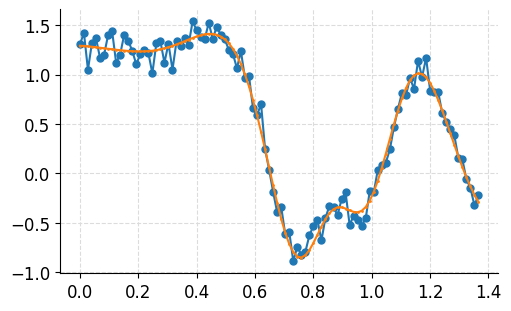

In [12]:
t_idx_max = 100

fig, ax = plt.subplots(1, 1, figsize=(5, 3))
dataset_name = "lorenz96_6d"
d = load_test_dataset(dataset_name)[0]
d1 = d.add_noise(0.1)
ax.plot(d.t[0, :t_idx_max], d1.u[0, :t_idx_max, 0], ".-", markersize=10)
ax.plot(d.t[0, :t_idx_max], d.u[0, :t_idx_max, 0], ".-", markersize=2)

In [4]:
import jax.numpy as jnp


dataset_name = "lorenz96_6d"

dataset_test, standardize = load_test_dataset(dataset_name)
ode_true = ODE_DICT[dataset_name]
u0_test = solve_batch(
    ode_true,
    jnp.arange(*ODE_BURN_IN_DICT[dataset_name]),
    jax.random.normal(jax.random.key(0), (5000, ode_true.dim)),
    rtol=1e-8,
    atol=1e-10,
)[:, -1]

t_long = jnp.concatenate((jnp.zeros(1), jnp.logspace(-2, 2, 10)))
t_lya = 1 / dataset_test.metadata["lyapunovs"][0]
u_test = solve_batch(ode_true, t_long * t_lya, u0_test, rtol=1e-8, atol=1e-10)
u_test = standardize(u_test)


In [10]:
sinkhorn_list = []
u_pred_list = []
for exp_type in tqdm(EXP_TYPES):
    model = load_experiment(dataset_name, exp_type, 0, 0.01)

    u_pred = solve_batch(model, t_long * t_lya, u_test[:, 0])
    sinkhorns = jax.lax.map(
        lambda x: sinkhorn_divergence(*x),
        (jnp.permute_dims(u_pred, (1, 0, 2)), jnp.permute_dims(u_test, (1, 0, 2))),
        batch_size=5,
    )
    u_pred_list.append(u_pred[:, -1])
    sinkhorn_list.append(sinkhorns)

100%|██████████| 3/3 [00:21<00:00,  7.03s/it]


Text(0, 0.5, 'Sinkhorn Divergence')

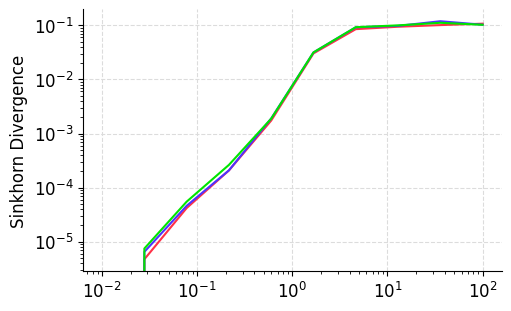

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
for sinkhorn, exp_type in zip(sinkhorn_list, EXP_TYPES):
    ax.plot(
        t_long,
        sinkhorn,
        label=LABEL_DICT[exp_type],
        color=COLOR_DICT[exp_type],
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylabel("Sinkhorn Divergence")
#ax.set_xlim((1, 100))
#ax.set_ylim((0.01, 0.2))

In [65]:
u_pred_list

[Array([[-1.11876386, -1.06397146,  1.16459527, ...,  0.57651369,
          0.84560038, -0.47387761],
        [ 0.23491201,  0.59424078, -0.78342733, ..., -0.18221278,
          0.51390373,  0.02995266],
        [ 0.79109995,  0.76050631, -0.01589502, ...,  1.85913856,
          0.44869274, -1.22588659],
        ...,
        [ 1.21717654, -0.61125697, -0.99966692, ..., -0.44251826,
         -1.8656682 , -0.53648276],
        [ 1.13468608, -1.20780683, -1.04444928, ..., -0.47160164,
         -1.86521051, -0.27434481],
        [ 1.24688997, -0.54066725, -0.99721067, ..., -1.49278065,
         -1.382754  , -1.2646313 ]], dtype=float64),
 Array([[ 0.90595847, -0.13370627, -1.70501622, ..., -0.41248035,
          1.54013266,  1.08935539],
        [-0.51622691,  1.54176907,  0.52428627, ..., -1.6027301 ,
          1.6030303 ,  0.46184774],
        [ 1.71320042,  1.33669847,  0.2159441 , ..., -0.0513129 ,
         -0.87700015,  0.85083288],
        ...,
        [ 2.13271647,  0.46797313, -0.0

In [55]:
u_pred_list[0].shape

(5000, 18)

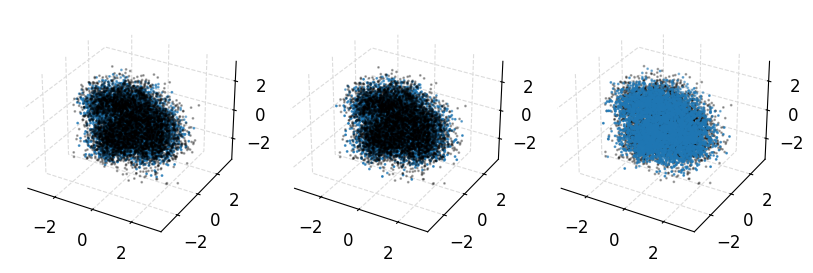

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(8, 5), subplot_kw={"projection": "3d"})
for i, ax in enumerate(axes):
    ax.scatter(*u_test[:, -1, :3].T, s=1, color="black", alpha=0.3)
    ax.scatter(*u_pred_list[i][:, :3].T, s=1)

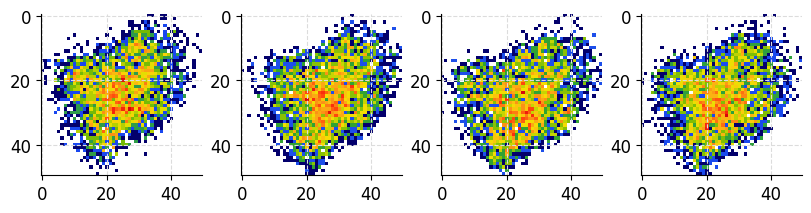

In [ ]:
import colorcet as cc
import matplotlib.colors as mcolors
import numpy as np


fig, axes = plt.subplots(1, 4, figsize=(8, 5))
hist, *bins = np.histogram2d(*u_test[:, -1, [0, 2]].T, bins=50)
axes[0].imshow(hist, cmap=cc.cm.rainbow4, norm=mcolors.LogNorm())
for i, ax in enumerate(axes[1:]):
    hist, *bins = np.histogram2d(*u_pred_list[i][:, [0, 2]].T, bins=50)
    ax.imshow(hist, cmap=cc.cm.rainbow4, norm=mcolors.LogNorm())
    # ax.scatter(*u_test[:, -1, :3].T, s=1, color="black", alpha=0.3)
    # ax.scatter(*u_pred_list[i][:, :3].T, s=1)

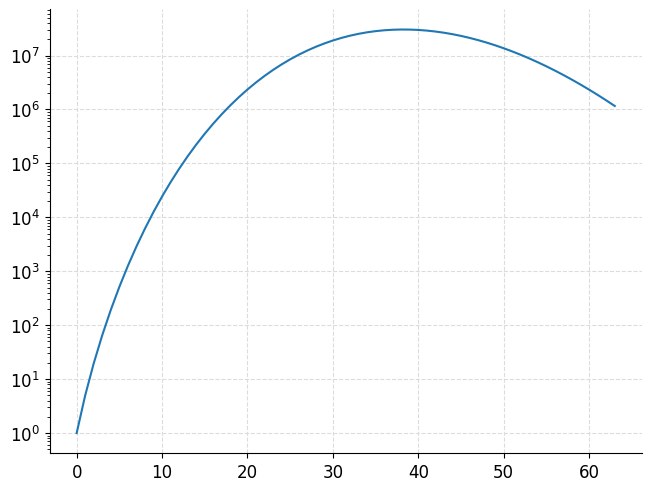

In [73]:
n = jnp.arange(0, 64)
v = (jnp.pi ** (0.5 * n)) * (2.5**n) / jax.scipy.special.gamma(1 + 0.5 * n)
plt.plot(n, v)
plt.yscale("log")